# ITAI 1371 Midterm: Stroke Prediction Data Preparation

**Research Question:** Can machine learning be used to classify stroke outcomes based on demographic, lifestyle, and health-related information?

**Dataset:** We are using the Stroke Prediction dataset (`dataset.csv`), which contains 43,400 records and 12 columns. The target variable is `stroke`, where `0` represents no stroke and `1` represents a stroke.

> This project is being completed for educational purposes as part of ITAI 1371. The model is not intended to be used as a medical diagnostic or prediction system.

## Notebook Overview

This notebook follows the main steps needed to prepare the dataset for machine learning:

1. Inspect the original dataset
2. Split the data into 70% training and 30% testing sets using stratification
3. Perform exploratory data analysis using only the training data
4. Create useful engineered features
5. Build a preprocessing pipeline using the training data
6. Compare the data before and after preprocessing
7. Examine the class imbalance in the `stroke` target
8. Save the raw and cleaned datasets, along with the preprocessing pipeline
9. Test the saved files to make sure they work correctly
10. Summarize the preprocessing decisions made during the project

**AI Disclosure:** *[The team will describe how AI tools were used to support the project, including code review, explanations, debugging, and documentation assistance.]*


## Setup

**In Colab:** click the folder icon on the left, upload `dataset.csv`, then run **Runtime → Run all**. If the file is missing, the setup cell will open an upload box.

In [ ]:
import os
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, precision_score

DATA_PATH = "dataset.csv"   # the original file -- never edited
RANDOM_STATE = 42           # same split for every teammate
plt.rcParams["figure.figsize"] = (8, 4.5)

# Colab: if dataset.csv has not been uploaded yet, ask for it instead of failing later.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists(DATA_PATH):
    if IN_COLAB:
        from google.colab import files
        print(f"{DATA_PATH} not found. Please upload it now.")
        uploaded = files.upload()
        if DATA_PATH not in uploaded:
            raise FileNotFoundError(f"Upload a file named exactly {DATA_PATH}.")
    else:
        raise FileNotFoundError(f"{DATA_PATH} not found. Put it in the same folder as this notebook.")
print("Using data file:", os.path.abspath(DATA_PATH))

dataset.csv not found. Please upload it now.


Saving dataset.csv to dataset.csv
Using data file: /content/dataset.csv


## Step 1: Data Inspection

First, we load the original dataset and review its basic structure. We check the number of rows and columns, the data types, missing values, and the distribution of the target variable.

At this point, we are only inspecting the dataset. We are not analyzing patterns or making preprocessing decisions yet, because those decisions should be based only on the training data after the train/test split.

In [ ]:
import pandas as pd

df = pd.read_csv("dataset.csv")

print(df.shape)
display(df.head())

(43400, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,30669,Male,3.0,0,0,No,children,Rural,95.12,18.0,NaN,0
1,30468,Male,58.0,1,0,Yes,Private,Urban,87.96,39.2,never smoked,0
2,16523,Female,8.0,0,0,No,Private,Urban,110.89,17.6,NaN,0
3,56543,Female,70.0,0,0,Yes,Private,Rural,69.04,35.9,formerly smoked,0
4,46136,Male,14.0,0,0,No,Never_worked,Rural,161.28,19.1,NaN,0


### Checking Data Types and Missing Values

Here I am checking what type of data is in each column and how many values are missing.

This helps me understand which columns are numbers, which are categories, and which columns will need to be cleaned later. BMI and smoking status have missing values, so those will need to be handled during preprocessing.

At this point, I am only reviewing the dataset and not making any changes yet.

In [ ]:
print("--- Data types ---")
print(df.dtypes)
print("\n--- Missing values per column ---")
print(df.isnull().sum())

--- Data types ---
id                     int64
gender                object
age                  float64
hypertension           int64
heart_disease          int64
ever_married          object
work_type             object
Residence_type        object
avg_glucose_level    float64
bmi                  float64
smoking_status        object
stroke                 int64
dtype: object

--- Missing values per column ---
id                       0
gender                   0
age                      0
hypertension             0
heart_disease            0
ever_married             0
work_type                0
Residence_type           0
avg_glucose_level        0
bmi                   1462
smoking_status       13292
stroke                   0
dtype: int64


### Checking Stroke Distribution and Duplicate Records

Here I am checking how many records belong to each stroke class and whether there are any duplicate rows or duplicate IDs.

The class percentages help show whether the target variable is balanced. Since the stroke cases make up a much smaller percentage of the dataset, this tells me that class imbalance will be something to consider later when the models are evaluated.

I am also checking for duplicate rows and duplicate IDs to make sure the dataset does not contain repeated records.

In [ ]:
print("--- Class distribution (stroke) ---")
counts = df["stroke"].value_counts()
print(counts)
print("\nPercent:")
print((df["stroke"].value_counts(normalize=True) * 100).round(2))

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate ids:", df["id"].duplicated().sum())

--- Class distribution (stroke) ---
stroke
0    42617
1      783
Name: count, dtype: int64

Percent:
stroke
0    98.2
1     1.8
Name: proportion, dtype: float64

Duplicate rows: 0
Duplicate ids: 0


### Verifying the Approved Dataset

Here I am checking that the dataset matches the version that was approved for the project.

These checks confirm:

- The dataset has **43,400 rows and 12 columns**.
- There are **42,617 records with `stroke = 0`** and **783 records with `stroke = 1`**.
- The `bmi` column has **1,462 missing values**.
- The `smoking_status` column has **13,292 missing values**.
- There are no duplicate rows or duplicate IDs.

The `assert` statements act as verification checks. If one of these values does not match, Python will stop and show an error, which means the dataset may not be the correct version.

No data is being changed in this step.

In [ ]:
# Verify the numbers from our planning stage. If any of these fail, the file is not the approved version.
assert df.shape == (43400, 12)
assert counts[0] == 42617 and counts[1] == 783
assert df["bmi"].isnull().sum() == 1462
assert df["smoking_status"].isnull().sum() == 13292
assert df.duplicated().sum() == 0 and df["id"].duplicated().sum() == 0
print("All planning numbers verified against the file.")

All planning numbers verified against the file.


## Step 2: Train/test split (70/30, stratified)

**Why split first?** Everything we learn from the data (medians, scaling values, which categories exist) must come from the training set. If we looked at the test set first, information would leak into our decisions and our final scores would look better than they really are.

**Why `stratify=y`?** Only 1.8% of rows are strokes. Stratifying guarantees both sets keep that same 1.8%.

In [ ]:
X = df.drop(columns=["stroke"])
y = df["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training rows:", len(X_train), "| Testing rows:", len(X_test))
print(f"Stroke rate - full:  {y.mean():.4%}")
print(f"Stroke rate - train: {y_train.mean():.4%}")
print(f"Stroke rate - test:  {y_test.mean():.4%}")
print("Stroke cases - train:", y_train.sum(), "| test:", y_test.sum())

Training rows: 30380 | Testing rows: 13020
Stroke rate - full:  1.8041%
Stroke rate - train: 1.8038%
Stroke rate - test:  1.8049%
Stroke cases - train: 548 | test: 235


### Saving the Raw Training and Testing Sets

After creating the 70/30 split, I save the training and testing partitions as separate CSV files.

This is important because it preserves the exact split used in the midterm so the same data can be reused later in the final project.

The files are saved before any preprocessing is applied, so they remain raw versions of the training and testing data.

In [ ]:
# Save the untouched partitions so the final project reuses the exact same split.
train_raw = X_train.assign(stroke=y_train)
test_raw = X_test.assign(stroke=y_test)
train_raw.to_csv("train_raw.csv", index=False)
test_raw.to_csv("test_raw.csv", index=False)
print("Saved train_raw.csv and test_raw.csv")

Saved train_raw.csv and test_raw.csv


## Step 3: Exploratory data analysis (training data only)

From here until the pipeline is built, every analysis uses `train_raw` only. The test set stays untouched.

In [ ]:
eda = train_raw.copy()   # a working copy for EDA so train_raw stays unchanged

### 3.1 Class imbalance

### Checking Class Imbalance in the Training Data

This graph shows how many training records belong to each stroke class.

- `stroke = 0` represents patients with no recorded stroke.
- `stroke = 1` represents patients with a recorded stroke.
- The dataset is highly imbalanced because stroke cases make up only a small percentage of the training data.
- This is important because a model could achieve high accuracy by predicting "no stroke" most of the time while still failing to identify stroke cases.
- Because of this imbalance, accuracy should not be used by itself when evaluating the models later.

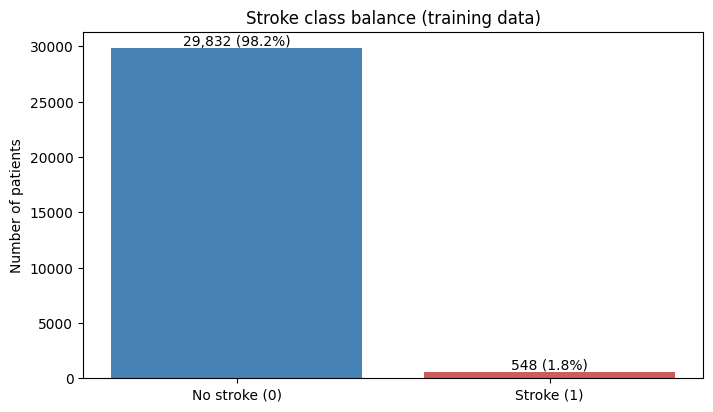

A model that always predicts 'no stroke' would be 98.2% accurate while finding zero strokes, so accuracy alone is misleading.


In [ ]:
class_counts = eda["stroke"].value_counts().sort_index()

fig, ax = plt.subplots()
ax.bar(["No stroke (0)", "Stroke (1)"], class_counts.values, color=["steelblue", "indianred"])
for i, v in enumerate(class_counts.values):
    ax.text(i, v, f"{v:,} ({v / len(eda):.1%})", ha="center", va="bottom")
ax.set_title("Stroke class balance (training data)")
ax.set_ylabel("Number of patients")
plt.show()

print(f"A model that always predicts 'no stroke' would be {1 - eda['stroke'].mean():.1%} accurate "
      "while finding zero strokes, so accuracy alone is misleading.")

### 3.2 Age distribution and stroke rate by age group

### Exploring Age and Stroke Rate

This step looks at the age distribution in the training data and compares the observed stroke rate across different age groups.

The ages are grouped into five ranges:

- 0–17
- 18–39
- 40–59
- 60–79
- 80+

The first graph shows how patients are distributed by age. The second graph shows the percentage of patients with `stroke = 1` within each age group.

This helps identify whether the recorded stroke outcome is associated with age in the training data. The results show that the observed stroke rate increases in the older age groups.

This is an association found in the dataset and does not prove that age by itself causes stroke.

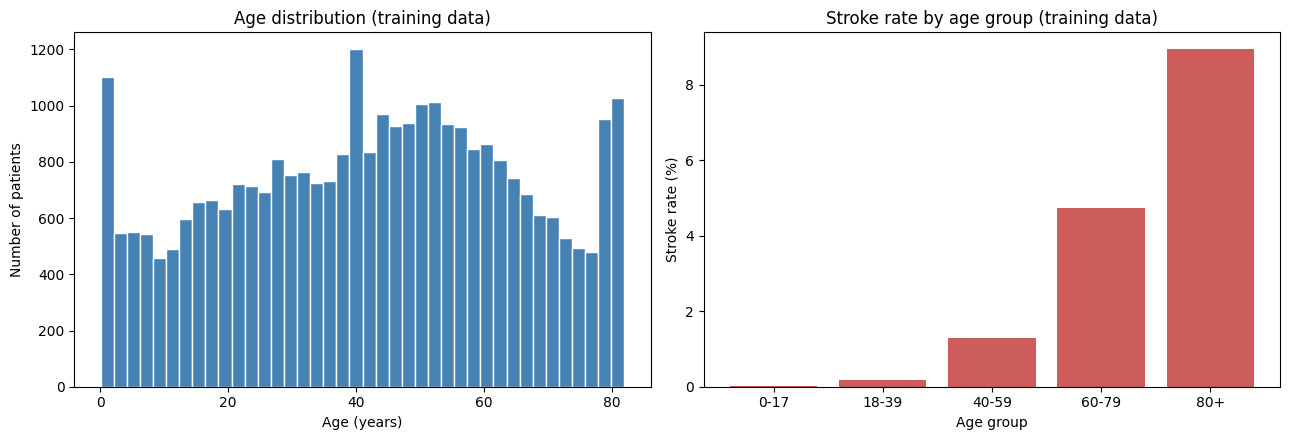

age_group
0-17     0.02
18-39    0.19
40-59    1.29
60-79    4.74
80+      8.94


In [ ]:
eda = train_raw.copy()
age_bins = [0, 18, 40, 60, 80, 120]
age_labels = ["0-17", "18-39", "40-59", "60-79", "80+"]
eda["age_group"] = pd.cut(eda["age"], bins=age_bins, labels=age_labels, right=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(eda["age"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Age distribution (training data)")
axes[0].set_xlabel("Age (years)")
axes[0].set_ylabel("Number of patients")

rate_by_age = eda.groupby("age_group", observed=True)["stroke"].mean() * 100
axes[1].bar(rate_by_age.index.astype(str), rate_by_age.values, color="indianred")
axes[1].set_title("Stroke rate by age group (training data)")
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Stroke rate (%)")
plt.tight_layout()
plt.show()

print(rate_by_age.round(2).to_string())

### Checking Fractional Ages

This step looks for patients who are recorded as being younger than 1 year old.

Some ages in the dataset are stored as fractions of a year instead of whole numbers. For example, a value below `1` represents an infant who is less than one year old.

The code counts how many patients are under age 1 and prints the smallest age values found in the training data.

This is useful because it confirms that the decimal age values are part of the dataset and should not automatically be treated as errors.

In [ ]:
# Unusual finding: infants. Ages below 1 are recorded as fractions of a year.
infants = eda[eda["age"] < 1]
print("Patients under 1 year old:", len(infants))
print("Smallest age values:", sorted(eda["age"].unique())[:8])

Patients under 1 year old: 348
Smallest age values: [np.float64(0.08), np.float64(0.16), np.float64(0.24), np.float64(0.32), np.float64(0.4), np.float64(0.48), np.float64(0.56), np.float64(0.64)]


### 3.3 BMI missingness and stroke outcome

### Checking Missing BMI Values

This step checks whether missing BMI values are related to different stroke rates in the training data.

First, a new temporary column called `bmi_is_missing` is created:

- `True` means the BMI value is missing.
- `False` means the BMI value is present.

The code then compares the stroke rate between patients with a recorded BMI and patients with a missing BMI.

This helps determine whether BMI missingness may contain useful information. Because the stroke rate is different between these two groups, we will keep track of whether BMI was originally missing when we preprocess the data later.

At this stage, no BMI values are being filled in yet. We are only studying the training data.

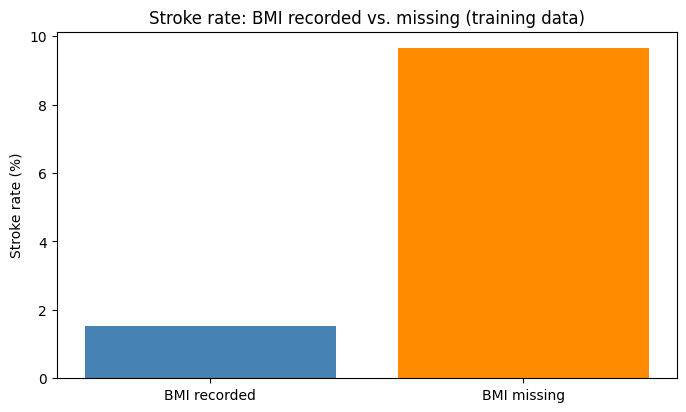

bmi_is_missing
False    1.54
True     9.65
Missing BMI rows in training: 995


In [ ]:
eda["bmi_is_missing"] = eda["bmi"].isnull()
bmi_missing_rate = eda.groupby("bmi_is_missing")["stroke"].mean() * 100

fig, ax = plt.subplots()
ax.bar(["BMI recorded", "BMI missing"], bmi_missing_rate.values, color=["steelblue", "darkorange"])
ax.set_title("Stroke rate: BMI recorded vs. missing (training data)")
ax.set_ylabel("Stroke rate (%)")
plt.show()

print(bmi_missing_rate.round(2).to_string())
print("Missing BMI rows in training:", eda["bmi_is_missing"].sum())

### 3.4 Smoking-status missingness by age

### Checking Missing Smoking Status by Age Group

This step looks at how often `smoking_status` is missing within each age group in the training data.

The code calculates the percentage of missing smoking-status values for each age range and displays the results in a bar chart.

This helps show whether the missing smoking information is distributed evenly across ages or whether some age groups have more missing values than others.

The dataset does not explain why the smoking-status values are missing, so I am only describing the pattern that appears in the training data and not assuming the reason for the missing values.

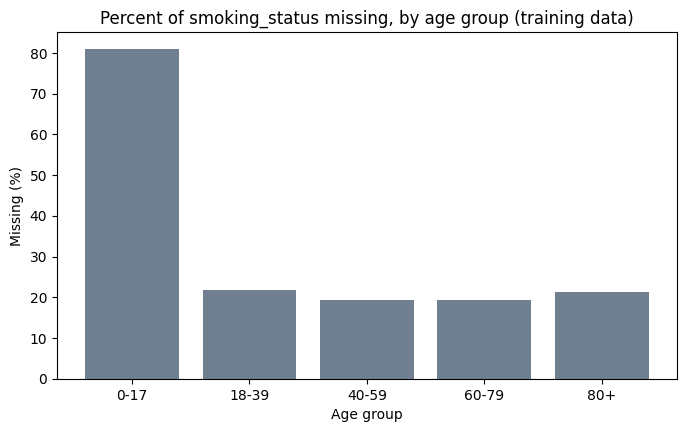

age_group
0-17     81.0
18-39    21.8
40-59    19.3
60-79    19.3
80+      21.2


In [ ]:
smoke_missing_by_age = eda.groupby("age_group", observed=True)["smoking_status"].apply(lambda s: s.isnull().mean() * 100)

fig, ax = plt.subplots()
ax.bar(smoke_missing_by_age.index.astype(str), smoke_missing_by_age.values, color="slategray")
ax.set_title("Percent of smoking_status missing, by age group (training data)")
ax.set_xlabel("Age group")
ax.set_ylabel("Missing (%)")
plt.show()

print(smoke_missing_by_age.round(1).to_string())

### Checking Smoking Status in Younger Age Groups

This step looks more closely at the `smoking_status` values for younger patients in the training data.

The code separates the data into two groups:

- Patients younger than 10
- Patients between ages 10 and 12

It then counts the smoking-status values in each group, including missing values.

This helps show how smoking information is recorded for younger patients and whether missing values are especially common in these age ranges.

The dataset does not explain why these values are missing, so I am only describing what appears in the data and not assuming the reason.

In [ ]:
# Unusual finding: smoking status for young children
under_10 = eda[eda["age"] < 10]
age_10_12 = eda[(eda["age"] >= 10) & (eda["age"] < 13)]
print("Under 10 - smoking_status values:")
print(under_10["smoking_status"].value_counts(dropna=False).to_string())
print("\nAges 10-12 - smoking_status values:")
print(age_10_12["smoking_status"].value_counts(dropna=False).to_string())

Under 10 - smoking_status values:
smoking_status
NaN    2985

Ages 10-12 - smoking_status values:
smoking_status
NaN                490
never smoked       179
formerly smoked     37
smokes               2


### 3.5 Glucose distribution and skewness

### Exploring Average Glucose Level

This step looks at the distribution of `avg_glucose_level` in the training data.

The histogram shows how the glucose values are spread across the patients. I also calculate the skewness and summary statistics to better understand the shape and range of the data.

A positive skewness value means the distribution has a longer tail toward higher glucose values. Since the skewness is above 1, the average glucose level is strongly right-skewed.

This is useful to know before preprocessing because the values are not evenly distributed and some values are much higher than most of the dataset.

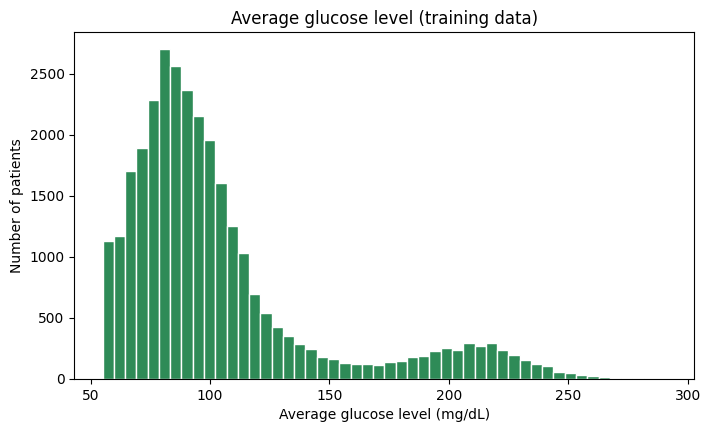

Skewness: 1.69  (0 = symmetric; above 1 = strongly right-skewed)
count    30380.00
mean       104.23
std         42.81
min         55.00
25%         77.53
50%         91.51
75%        111.76
max        291.05


In [ ]:
fig, ax = plt.subplots()
ax.hist(eda["avg_glucose_level"], bins=50, color="seagreen", edgecolor="white")
ax.set_title("Average glucose level (training data)")
ax.set_xlabel("Average glucose level (mg/dL)")
ax.set_ylabel("Number of patients")
plt.show()

print(f"Skewness: {eda['avg_glucose_level'].skew():.2f}  (0 = symmetric; above 1 = strongly right-skewed)")
print(eda["avg_glucose_level"].describe().round(2).to_string())

### 3.6 BMI outliers

### Checking BMI Range and Possible Outliers

This step looks at the distribution of BMI values in the training data and checks for unusually high values.

The box plot helps show the typical BMI range and highlights values that are far from most of the other observations.

I also check how many BMI values are above 60, how many stroke cases are in that group, the ages of those patients, and the overall BMI range in the training data.

These high BMI values are unusual, but the dataset does not give enough information to determine whether they are errors. Because of that, I will keep them rather than automatically removing them.

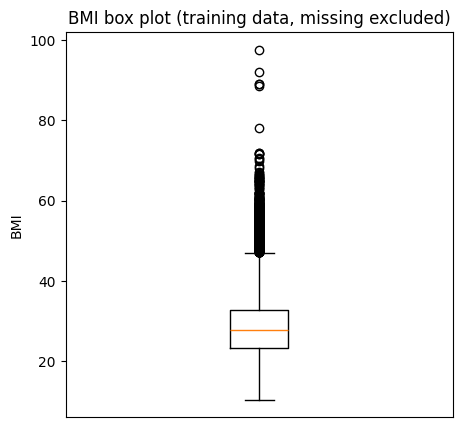

BMI above 60: 65 rows | strokes among them: 0
Ages of those rows: {'count': 65.0, 'mean': 44.5, 'std': 13.1, 'min': 17.0, '25%': 36.0, '50%': 44.0, '75%': 54.0, 'max': 78.0}
BMI range: 10.5 to 97.6


In [ ]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.boxplot(eda["bmi"].dropna())
ax.set_title("BMI box plot (training data, missing excluded)")
ax.set_ylabel("BMI")
ax.set_xticks([])
plt.show()

high_bmi = eda[eda["bmi"] > 60]
print("BMI above 60:", len(high_bmi), "rows | strokes among them:", high_bmi["stroke"].sum())
print("Ages of those rows:", high_bmi["age"].describe().round(1).to_dict())
print("BMI range:", eda["bmi"].min(), "to", eda["bmi"].max())

### 3.7 Hypertension and heart disease

### Comparing Stroke Rate by Hypertension and Heart Disease

This step compares the observed stroke rate for patients with and without hypertension and heart disease in the training data.

The code creates two bar charts:

- One compares stroke rates for patients with and without hypertension.
- The other compares stroke rates for patients with and without heart disease.

This helps show whether these health conditions are associated with different stroke rates in the training data.

These results show an association in the dataset, but they do not prove that hypertension or heart disease directly causes stroke.

hypertension {0: 1.5, 1: 4.78}
heart_disease {0: 1.41, 1: 9.63}


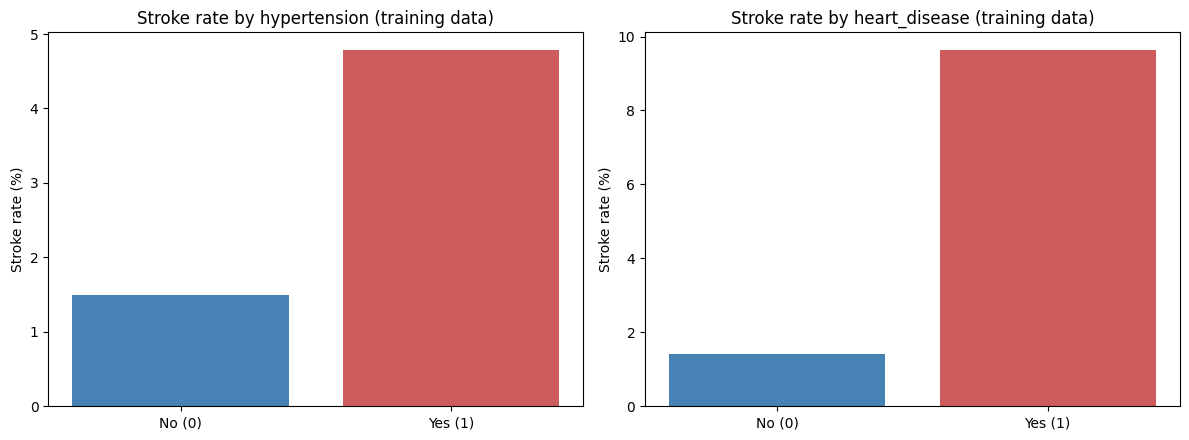

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, ["hypertension", "heart_disease"]):
    rate = eda.groupby(col)["stroke"].mean() * 100
    ax.bar(["No (0)", "Yes (1)"], rate.values, color=["steelblue", "indianred"])
    ax.set_title(f"Stroke rate by {col} (training data)")
    ax.set_ylabel("Stroke rate (%)")
    print(col, rate.round(2).to_dict())
plt.tight_layout()
plt.show()

### Checking Other Categorical Features

This step looks at two additional categorical variables in the training data: `gender` and `work_type`.

First, I count how many records belong to each gender category. This helps check whether any categories are very rare.

Then, I calculate the stroke rate for each `work_type` category to see whether the recorded stroke outcome differs across types of employment.

These checks are part of the exploratory data analysis and are only describing patterns in the training data. They do not show cause and effect.

In [ ]:
# Other categorical checks
print(eda["gender"].value_counts().to_string())
print("\nStroke rate by work_type (%):")
print((eda.groupby("work_type")["stroke"].mean() * 100).round(2).to_string())

gender
Female    17940
Male      12430
Other        10

Stroke rate by work_type (%):
work_type
Govt_job         1.73
Never_worked     0.00
Private          1.75
Self-employed    3.69
children         0.02


### EDA Findings (Training Data)

- **Class imbalance:** Only about 1.8% of the training records have `stroke = 1`. Because of this imbalance, accuracy alone may give a misleading picture of model performance.

- **Age:** The observed stroke rate increases across the older age groups. Age appears to have one of the clearest relationships with the recorded stroke outcome in the training data.

- **BMI missingness:** Records with missing BMI values have a different observed stroke rate than records with a reported BMI. Because the missingness may contain useful information, I will keep track of it with a `bmi_missing` feature.

- **Smoking status:** Missing smoking-status values are much more common in younger age groups. The dataset does not explain why these values are missing, so I will preserve them as an `Unknown` category instead of guessing or replacing them with the most common category.

- **Glucose:** `avg_glucose_level` is strongly right-skewed, meaning most values are lower while a smaller number of records have much higher glucose values.

- **BMI outliers:** Some BMI values are much higher than most of the dataset. There is not enough information to determine whether these values are errors, so I will keep them and use `RobustScaler` during preprocessing to reduce the influence of extreme values.

- **Fractional ages:** The dataset contains ages below one year, recorded as fractions of a year. These values will be kept rather than automatically removed.

- **Gender:** The `Other` gender category contains very few records, but it will still be kept as its own category.

## Step 4: Feature Engineering

This step creates a few additional features and converts some text values into a format that will be easier to use during preprocessing.

These changes use fixed rules rather than values calculated from the dataset, so the same rules can be applied to both the training and testing data.

- **`bmi_missing`:** Records whether BMI was originally missing. A value of `1` means BMI was missing and `0` means it was present. This is created before the missing BMI values are filled.
- **`smoking_status`:** Missing values are changed to `"Unknown"` instead of guessing a smoking category.
- **`age_group`:** Age is grouped into fixed ranges: 0–17, 18–39, 40–59, 60–79, and 80+.
- **`ever_married`:** `"Yes"` is converted to `1` and `"No"` to `0`.
- **`Residence_type`:** `"Urban"` is converted to `1` and `"Rural"` to `0`.
- **`id`:** The ID column is removed from the model features because it only identifies each record and does not describe the patient.

### Why use a separate Python file?

The feature-engineering function will be saved in `feature_engineering.py`. Keeping the function in a separate importable file makes it easier for the saved `full_pipeline.joblib` pipeline to reload and use the same feature-engineering rules in a future notebook or Python session.

The `feature_engineering.py` file should be kept with `full_pipeline.joblib` for the final project.

In [ ]:
%%writefile feature_engineering.py
"""Leakage-safe feature engineering for the ITAI 1371 stroke dataset.

Every rule here uses fixed constants (no values learned from data), so the
same function can be applied to training, testing, and new data.
Keep this file next to full_pipeline.joblib: the pipeline imports it on load.
"""
import numpy as np
import pandas as pd

AGE_BINS = [0, 18, 40, 60, 80, 120]
AGE_LABELS = ["0-17", "18-39", "40-59", "60-79", "80+"]
GLUCOSE_BINS = [0, 100, 126, np.inf]
GLUCOSE_LABELS = ["Normal", "Elevated", "High"]
ADDED_COLUMNS = ["bmi_missing", "age_group", "glucose_category"]


def engineer_features(data):
    """Return a copy of the raw feature table with engineered columns added and `id` dropped."""
    out = pd.DataFrame(data).copy()
    out["bmi_missing"] = out["bmi"].isnull().astype(int)        # flag BEFORE imputation
    out["smoking_status"] = out["smoking_status"].fillna("Unknown")
    out["age_group"] = pd.cut(out["age"], bins=AGE_BINS, labels=AGE_LABELS, right=False).astype(str)
    out["glucose_category"] = pd.cut(
        out["avg_glucose_level"], bins=GLUCOSE_BINS, labels=GLUCOSE_LABELS, right=False
    ).astype(str)
    out["ever_married"] = (out["ever_married"] == "Yes").astype(int)
    out["Residence_type"] = (out["Residence_type"] == "Urban").astype(int)
    # errors="ignore" lets the pipeline accept new data that has no id or stroke column
    return out.drop(columns=["id", "stroke"], errors="ignore")


def engineered_feature_names(transformer, input_features):
    """Output column names for FunctionTransformer(feature_names_out=...)."""
    kept = [c for c in input_features if c not in ("id", "stroke")]
    return np.array(kept + ADDED_COLUMNS, dtype=object)

Overwriting feature_engineering.py


### Applying and Checking Feature Engineering

This step imports the feature-engineering function that was saved in `feature_engineering.py` and applies it to both the training and testing features.

The same fixed feature-engineering rules are used for both datasets. This keeps the transformations consistent without learning anything from the test data.

The code also checks that the age-group definitions used in the feature-engineering file match the age groups used during EDA.

Finally, I preview the transformed training data and check which new features were created.

In [ ]:
import feature_engineering
importlib.reload(feature_engineering)  # pick up edits if the cell above is re-run
from feature_engineering import engineer_features, engineered_feature_names, AGE_BINS, AGE_LABELS

# The module must use the same age groups as the EDA in Step 3.
assert AGE_BINS == age_bins and AGE_LABELS == age_labels

X_train_fe = engineer_features(X_train)
X_test_fe = engineer_features(X_test)

print("New columns:", [c for c in X_train_fe.columns if c not in X_train.columns])
X_train_fe.head()

New columns: ['bmi_missing', 'age_group', 'glucose_category']


,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,bmi_missing,age_group,glucose_category
5473,Male,7.0,0,0,0,children,0,102.78,18.1,Unknown,0,0-17,Elevated
26630,Female,53.0,0,1,0,Private,1,94.68,NaN,never smoked,1,40-59,Normal
17083,Male,26.0,0,0,0,Private,0,88.28,36.3,never smoked,0,18-39,Normal
4730,Male,7.0,0,0,0,children,1,77.12,18.6,Unknown,0,0-17,Normal
19154,Female,44.0,0,0,1,Private,1,84.55,44.5,Unknown,0,40-59,Normal


## Step 5: Preprocessing Pipeline

This step builds the preprocessing pipeline that prepares the engineered features for machine learning.

A `ColumnTransformer` allows different preprocessing steps to be applied to different groups of columns. The feature-engineering step and preprocessing step are then combined into one `full_pipeline`.

The pipeline is **fit using the training data only**. This means that values such as medians, scaling information, and category lists are learned only from the training set. The same learned rules are then used to transform both the training and testing data.

| Columns | Preprocessing | What is learned from training data |
|---|---|---|
| `age`, `avg_glucose_level` | `RobustScaler` | Median and interquartile range (IQR) |
| `bmi` | Median `SimpleImputer`, then `RobustScaler` | Median BMI, then median and IQR |
| `gender`, `work_type`, `smoking_status`, `age_group` | `OneHotEncoder(handle_unknown="ignore")` | Categories found in the training data |
| `hypertension`, `heart_disease`, `ever_married`, `Residence_type`, `bmi_missing` | Passed through unchanged | Nothing |

The complete pipeline allows raw data to go through feature engineering and preprocessing in one process:

`raw data → feature engineering → preprocessing → model-ready data`

### Building and Applying the Preprocessing Pipeline

This cell builds the preprocessing pipeline and applies it to the raw training and testing features.

Different types of columns require different preparation:

- `age` and `avg_glucose_level` are scaled using `RobustScaler`.
- Missing BMI values are filled using the median BMI from the training data, then BMI is scaled.
- Categorical features are converted into numeric columns using one-hot encoding.
- Binary features that are already represented as 0/1 are kept unchanged.

The full pipeline first performs feature engineering and then preprocessing.

The pipeline is fitted only on the training data. This allows it to learn values such as the median BMI, scaling values, and category names without using information from the test set.

After fitting, the same learned preprocessing rules are applied to both the training and testing data.

In [ ]:
scale_cols = ["age", "avg_glucose_level"]
bmi_cols = ["bmi"]
cat_cols = ["gender", "work_type", "smoking_status", "age_group", "glucose_category"]
binary_cols = ["hypertension", "heart_disease", "ever_married", "Residence_type", "bmi_missing"]

bmi_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", RobustScaler()),
])

preprocessor = ColumnTransformer([
    ("scale", RobustScaler(), scale_cols),
    ("bmi", bmi_pipeline, bmi_cols),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("binary", "passthrough", binary_cols),
])

full_pipeline = Pipeline([
    ("features", FunctionTransformer(engineer_features, feature_names_out=engineered_feature_names)),
    ("preprocess", preprocessor),
])

full_pipeline.fit(X_train, y_train)                # learn from TRAINING data only (raw rows in)
X_train_prep = full_pipeline.transform(X_train)
X_test_prep = full_pipeline.transform(X_test)      # apply what was learned; never fit on test
preprocessor = full_pipeline.named_steps["preprocess"]  # the fitted ColumnTransformer

feature_names = full_pipeline.get_feature_names_out()
X_train_clean = pd.DataFrame(X_train_prep, columns=feature_names, index=X_train.index)
X_test_clean = pd.DataFrame(X_test_prep, columns=feature_names, index=X_test.index)

print("Prepared training shape:", X_train_clean.shape)
print("Prepared testing shape: ", X_test_clean.shape)
print("Median BMI learned from training data:", preprocessor.named_transformers_["bmi"].named_steps["impute"].statistics_[0])
X_train_clean.head()

Prepared training shape: (30380, 28)
Prepared testing shape:  (13020, 28)
Median BMI learned from training data: 27.7


,scale__age,scale__avg_glucose_level,bmi__bmi,onehot__gender_Female,onehot__gender_Male,onehot__gender_Other,onehot__work_type_Govt_job,onehot__work_type_Never_worked,onehot__work_type_Private,onehot__work_type_Self-employed,...,onehot__age_group_60-79,onehot__age_group_80+,onehot__glucose_category_Elevated,onehot__glucose_category_High,onehot__glucose_category_Normal,binary__hypertension,binary__heart_disease,binary__ever_married,binary__Residence_type,binary__bmi_missing
5473,-1.027778,0.329243,-1.043478,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26630,0.250000,0.092609,0.000000,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
17083,-0.500000,-0.094362,0.934783,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
4730,-1.027778,-0.420391,-0.989130,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
19154,0.000000,-0.203330,1.826087,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0


### Validating the Preprocessed Data

This step checks that the preprocessing pipeline produced the expected results.

First, I verify that:

- No missing values remain in either the training or testing data.
- The training and testing sets contain the same processed feature columns.

I also check that running the complete `full_pipeline` gives the same result as performing feature engineering and preprocessing separately.

These checks help confirm that the pipeline is working consistently before the prepared data is saved or used for machine learning.

In [ ]:
# Checks: the prepared data must be fully numeric with no missing values.
assert X_train_clean.isnull().sum().sum() == 0 and X_test_clean.isnull().sum().sum() == 0
assert list(X_train_clean.columns) == list(X_test_clean.columns)
print("No missing values remain, and train/test have identical columns.")

# The full pipeline must give exactly the same result as running the two steps by hand.
assert np.allclose(X_train_prep, preprocessor.transform(X_train_fe))
assert np.allclose(X_test_prep, preprocessor.transform(X_test_fe))
print("full_pipeline output matches feature engineering + preprocessor applied step by step.")

No missing values remain, and train/test have identical columns.
full_pipeline output matches feature engineering + preprocessor applied step by step.


## Step 6: Before-and-after visualizations (training data)

### Comparing Missing Values Before and After Preprocessing

This step compares missing values in the raw training features with the prepared training data.

The first graph shows how many missing values appear in each column before preprocessing. The second graph shows the total number of missing values remaining after the preprocessing pipeline is applied.

This helps confirm that the missing BMI and smoking-status values were handled successfully and that the prepared training data contains no missing values.

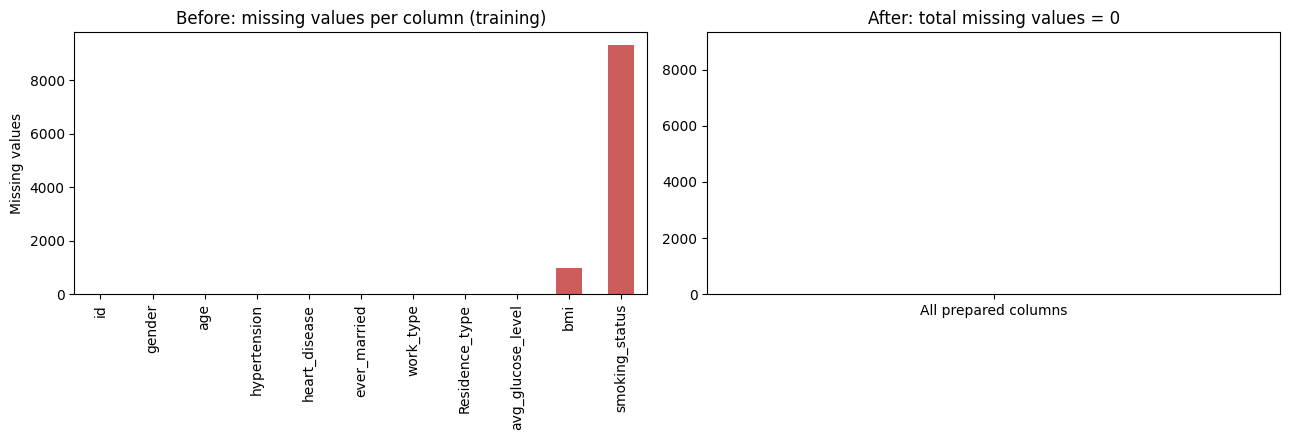

In [ ]:
# 6.1 Missing values per column: before vs. after
before_missing = X_train.isnull().sum()
after_missing = X_train_clean.isnull().sum().sum()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
before_missing.plot(kind="bar", ax=axes[0], color="indianred")
axes[0].set_title("Before: missing values per column (training)")
axes[0].set_ylabel("Missing values")
axes[1].bar(["All prepared columns"], [after_missing], color="seagreen")
axes[1].set_ylim(0, before_missing.max())
axes[1].set_title(f"After: total missing values = {after_missing}")
plt.tight_layout()
plt.show()

### Comparing BMI Before and After Imputation

This step shows how the BMI distribution changes after missing BMI values are filled using the median BMI learned from the training data.

The first histogram shows the recorded BMI values before imputation, with missing values left out.

The second histogram shows BMI after the missing values have been replaced with the training-set median.

The BMI values are shown before scaling so the original BMI units are still easy to interpret.

Because many missing values are replaced with the same median value, a taller bar appears around the median. This is one reason the `bmi_missing` feature is also kept, so the model can tell which BMI values were originally missing.

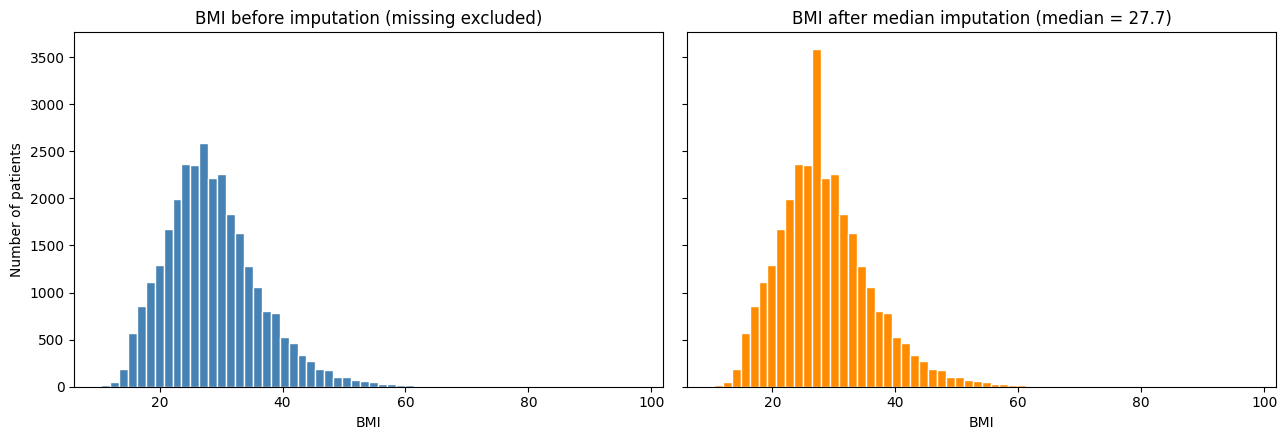

Note the taller bar at the median: imputation adds a spike, which is why we also keep bmi_missing.


In [ ]:
# 6.2 BMI before vs. after median imputation (unscaled, so the units stay readable)
median_bmi = preprocessor.named_transformers_["bmi"].named_steps["impute"].statistics_[0]
bmi_after_impute = X_train["bmi"].fillna(median_bmi)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
axes[0].hist(X_train["bmi"].dropna(), bins=60, color="steelblue", edgecolor="white")
axes[0].set_title("BMI before imputation (missing excluded)")
axes[1].hist(bmi_after_impute, bins=60, color="darkorange", edgecolor="white")
axes[1].set_title(f"BMI after median imputation (median = {median_bmi})")
for ax in axes:
    ax.set_xlabel("BMI")
axes[0].set_ylabel("Number of patients")
plt.tight_layout()
plt.show()
print("Note the taller bar at the median: imputation adds a spike, which is why we also keep bmi_missing.")

### Comparing Age and Glucose Before and After Scaling

This step compares the original values of `age` and `avg_glucose_level` with the values produced after applying `RobustScaler`.

The graphs on the left show the original training data. The graphs on the right show the scaled versions used by the machine learning pipeline.

`RobustScaler` centers the data around the median and scales it using the interquartile range (IQR). This helps reduce the influence of extreme values while keeping the overall shape of the distribution similar.

Scaling changes the numerical representation of the features, but it does not remove records or change the order of the values.

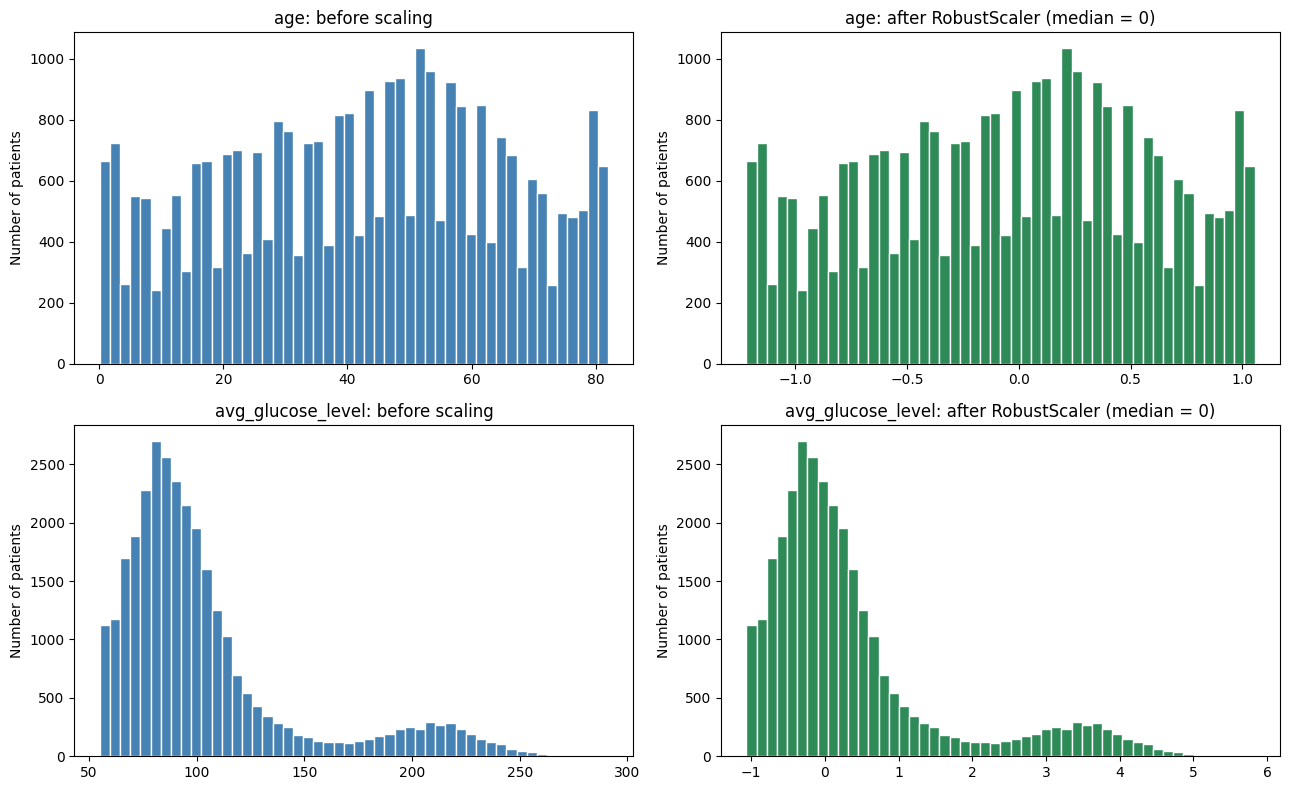

In [ ]:
# 6.3 Age and glucose before vs. after scaling
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, col in enumerate(["age", "avg_glucose_level"]):
    axes[row, 0].hist(X_train[col], bins=50, color="steelblue", edgecolor="white")
    axes[row, 0].set_title(f"{col}: before scaling")
    axes[row, 1].hist(X_train_clean[f"scale__{col}"], bins=50, color="seagreen", edgecolor="white")
    axes[row, 1].set_title(f"{col}: after RobustScaler (median = 0)")
    for ax in axes[row]:
        ax.set_ylabel("Number of patients")
plt.tight_layout()
plt.show()

### Confirming the Stratified Train/Test Split

This step compares the percentage of stroke cases in the training and testing sets.

Because `stratify=y` was used during the 70/30 split, both sets should have nearly the same stroke rate as the original dataset.

The bar chart provides a quick visual check that the class distribution was preserved during the split.

This does not use the test set to make any preprocessing or modeling decisions. It is only confirming that the stratified split worked as expected.

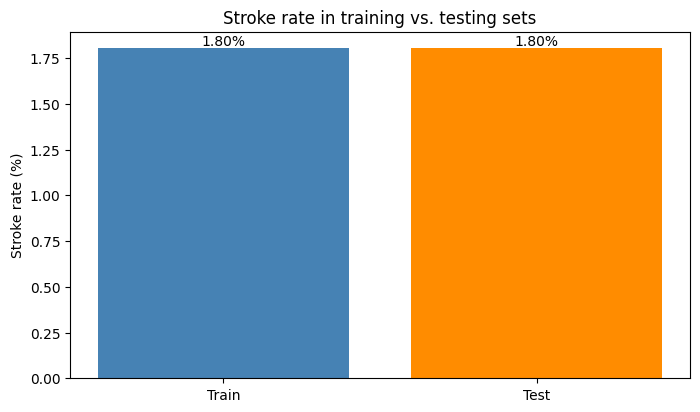

In [ ]:
# 6.4 Stroke class balance: train vs. test (confirms stratification)
fig, ax = plt.subplots()
ax.bar(["Train", "Test"], [y_train.mean() * 100, y_test.mean() * 100], color=["steelblue", "darkorange"])
ax.set_title("Stroke rate in training vs. testing sets")
ax.set_ylabel("Stroke rate (%)")
for i, v in enumerate([y_train.mean() * 100, y_test.mean() * 100]):
    ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom")
plt.show()

### Comparing Raw and Prepared Records

This step shows a few training records before and after preprocessing.

The first table displays the original raw values. The second table shows how those same records look after feature engineering, missing-value handling, scaling, and one-hot encoding.

This gives a simple visual example of how the preprocessing pipeline converts the original dataset into a fully numeric, model-ready format.

In [ ]:
# 6.5 Sample records: before vs. after
print("BEFORE (raw training rows):")
display(X_train.head(3))
print("AFTER (prepared training rows):")
display(X_train_clean.head(3))

BEFORE (raw training rows):


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status
5473,15355,Male,7.0,0,0,No,children,Rural,102.78,18.1,NaN
26630,62588,Female,53.0,0,1,No,Private,Urban,94.68,NaN,never smoked
17083,28722,Male,26.0,0,0,No,Private,Rural,88.28,36.3,never smoked


AFTER (prepared training rows):


,scale__age,scale__avg_glucose_level,bmi__bmi,onehot__gender_Female,onehot__gender_Male,onehot__gender_Other,onehot__work_type_Govt_job,onehot__work_type_Never_worked,onehot__work_type_Private,onehot__work_type_Self-employed,...,onehot__age_group_60-79,onehot__age_group_80+,onehot__glucose_category_Elevated,onehot__glucose_category_High,onehot__glucose_category_Normal,binary__hypertension,binary__heart_disease,binary__ever_married,binary__Residence_type,binary__bmi_missing
5473,-1.027778,0.329243,-1.043478,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
26630,0.250000,0.092609,0.000000,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0
17083,-0.500000,-0.094362,0.934783,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0


## Step 7: Class imbalance

We do **not** resample the saved data, and we never resample the test set. Instead, we calculate **class weights** from the training labels. In the final project, models will use `class_weight="balanced"`, which tells the model that missing a stroke case costs much more than a false alarm.

### Calculating Balanced Class Weights

Because stroke cases make up only a small percentage of the training data, the two target classes are highly imbalanced.

This step calculates balanced class weights using only the training target values.

Balanced class weights give more influence to the minority class and less influence to the majority class during model training. This can help models pay more attention to the less common stroke cases.

These weights are calculated here for later use with models that support class weighting. They do not change or duplicate any rows in the dataset.

In [ ]:
classes = np.array([0, 1])
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
print({int(c): round(w, 2) for c, w in zip(classes, weights)})
print(f"Each stroke case counts about {weights[1] / weights[0]:.0f}x as much as a non-stroke case during training.")

{0: np.float64(0.51), 1: np.float64(27.72)}
Each stroke case counts about 54x as much as a non-stroke case during training.


### Demonstrating the Accuracy Trap with a Baseline Model

This step uses a `DummyClassifier` as a simple baseline.

The dummy model always predicts the most common class, which is `stroke = 0`.

Because the dataset is highly imbalanced, this model can still achieve very high accuracy even though it does not identify any stroke cases.

Five-fold stratified cross-validation is used on the training data only. The test set remains untouched.

Preprocessing is included inside the cross-validation pipeline so that each fold learns its preprocessing rules only from the training portion of that fold.

In [ ]:
# Demonstrating the accuracy trap with cross-validation on TRAINING data only (the test set stays untouched).
dummy = DummyClassifier(strategy="most_frequent")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scores = cross_validate(dummy, X_train_clean, y_train, cv=cv,
                        scoring={"accuracy": "accuracy", "recall": "recall", "f1": "f1",
                                 # zero_division=0: precision is 0 when the model never predicts a stroke
                                 "precision": make_scorer(precision_score, zero_division=0)})
for metric in ["accuracy", "recall", "precision", "f1"]:
    print(f"{metric:>9}: {scores['test_' + metric].mean():.3f}")
print("\nHigh accuracy, zero recall: this baseline finds no strokes. The final project's models must beat it on recall and F1.")

 accuracy: 0.982
   recall: 0.000
precision: 0.000
       f1: 0.000

High accuracy, zero recall: this baseline finds no strokes. The final project's models must beat it on recall and F1.


## Step 8: Save outputs for the final project

| File | Contents |
|---|---|
| `train_raw.csv`, `test_raw.csv` | The untouched 70/30 split (all original columns, including `id` and `stroke`) |
| `train_clean.csv`, `test_clean.csv` | Model-ready features plus `stroke` |
| `full_pipeline.joblib` | Fitted feature engineering + preprocessing (raw rows in, clean features out) |
| `feature_engineering.py` | The module `full_pipeline.joblib` needs on load; keep the two files together |

### Saving the Cleaned Data and Preprocessing Files

This step saves the prepared training and testing datasets along with the fitted preprocessing pipeline.

The `stroke` target is added back to the cleaned feature tables before they are saved as CSV files.

The fitted `full_pipeline` is also saved as `full_pipeline.joblib` so the same feature-engineering and preprocessing steps can be reused later without rebuilding them from scratch.

Finally, the code checks that all expected output files were created and prints the size of each file.

In [ ]:
train_clean = X_train_clean.assign(stroke=y_train.values)
test_clean = X_test_clean.assign(stroke=y_test.values)
train_clean.to_csv("train_clean.csv", index=False)
test_clean.to_csv("test_clean.csv", index=False)
joblib.dump(full_pipeline, "full_pipeline.joblib")   # feature engineering + preprocessing, fitted on training data

OUTPUT_FILES = ["train_raw.csv", "test_raw.csv", "train_clean.csv", "test_clean.csv",
                "full_pipeline.joblib", "feature_engineering.py"]
for f in OUTPUT_FILES:
    print(f"Saved {f:<24} {os.path.getsize(f):>12,} bytes")

Saved train_raw.csv               1,880,552 bytes
Saved test_raw.csv                  805,917 bytes
Saved train_clean.csv             4,816,479 bytes
Saved test_clean.csv              2,063,371 bytes
Saved full_pipeline.joblib            5,850 bytes
Saved feature_engineering.py          1,699 bytes


## Step 9: Test the Saved Outputs

This step reloads the saved files from disk to make sure they can be used correctly in the final project.

I check that the saved datasets and pipeline are complete, consistent, and able to reproduce the expected preprocessing results.

If any of the checks fail, Python will stop with an error. This helps catch problems before the files are reused later.

### Verifying the Saved Files and Pipeline

This step reloads all of the saved outputs to make sure they are complete and can be reused later.

The checks confirm that:

- The raw training and testing files still contain all original rows and columns.
- The train and test sets do not overlap.
- The stroke proportion remains nearly the same in both sets.
- The cleaned files have the expected number of rows and columns.
- The cleaned data contains only numeric values and no missing values.
- The `stroke` target still matches the original raw files.
- The saved preprocessing pipeline can transform the raw data and reproduce the saved cleaned datasets.

If any of these checks fail, Python will stop with an error. If all checks pass, the saved outputs are consistent and ready for the final project.

In [ ]:
# Reload everything from disk
train_raw_chk = pd.read_csv("train_raw.csv")
test_raw_chk = pd.read_csv("test_raw.csv")
train_clean_chk = pd.read_csv("train_clean.csv")
test_clean_chk = pd.read_csv("test_clean.csv")
pipeline_chk = joblib.load("full_pipeline.joblib")

# Raw split: correct sizes, no overlap, nothing lost, original columns kept
assert len(train_raw_chk) + len(test_raw_chk) == len(df)
assert set(train_raw_chk["id"]).isdisjoint(test_raw_chk["id"])
assert list(train_raw_chk.columns) == list(df.columns) == list(test_raw_chk.columns)
assert abs(train_raw_chk["stroke"].mean() - test_raw_chk["stroke"].mean()) < 0.001   # stratified

# Clean files: same rows as raw files, same columns, fully numeric, no missing values
assert train_clean_chk.shape == (len(train_raw_chk), len(feature_names) + 1)
assert test_clean_chk.shape == (len(test_raw_chk), len(feature_names) + 1)
assert list(train_clean_chk.columns) == list(test_clean_chk.columns) == list(feature_names) + ["stroke"]
assert train_clean_chk.isnull().sum().sum() == 0 and test_clean_chk.isnull().sum().sum() == 0
assert all(pd.api.types.is_numeric_dtype(t) for t in train_clean_chk.dtypes)
assert (train_clean_chk["stroke"].values == train_raw_chk["stroke"].values).all()
assert (test_clean_chk["stroke"].values == test_raw_chk["stroke"].values).all()

# Saved pipeline: raw test rows in -> exactly the saved clean test rows out
reproduced = pipeline_chk.transform(test_raw_chk.drop(columns=["stroke"]))
assert np.allclose(reproduced, test_clean_chk.drop(columns=["stroke"]).values)
reproduced_train = pipeline_chk.transform(train_raw_chk.drop(columns=["stroke"]))
assert np.allclose(reproduced_train, train_clean_chk.drop(columns=["stroke"]).values)

print("train_raw.csv:  ", train_raw_chk.shape, "| test_raw.csv:  ", test_raw_chk.shape)
print("train_clean.csv:", train_clean_chk.shape, "| test_clean.csv:", test_clean_chk.shape)
print("All output checks passed: the saved pipeline reproduces the saved clean files exactly.")

train_raw.csv:   (30380, 12) | test_raw.csv:   (13020, 12)
train_clean.csv: (30380, 29) | test_clean.csv: (13020, 29)
All output checks passed: the saved pipeline reproduces the saved clean files exactly.


### Testing the Pipeline on New Data

This step checks whether the saved preprocessing pipeline can handle a brand-new patient record that was not part of the original dataset.

The new record does not include an `id` or `stroke` column, and it also contains missing values for BMI and smoking status.

The pipeline should automatically:

- create the engineered features
- handle the missing BMI value
- replace the missing smoking status with `"Unknown"`
- encode the categorical values
- scale the numerical features
- return a fully numeric row with no missing values

This confirms that the saved pipeline can be reused later with new raw data.

In [ ]:
# The pipeline also works on a brand-new patient (no id, no stroke column, missing BMI and smoking status)
new_patient = pd.DataFrame([{
    "gender": "Female", "age": 67, "hypertension": 1, "heart_disease": 0, "ever_married": "Yes",
    "work_type": "Private", "Residence_type": "Urban", "avg_glucose_level": 180.5,
    "bmi": np.nan, "smoking_status": np.nan,
}])
new_row = pd.DataFrame(pipeline_chk.transform(new_patient), columns=feature_names)
assert new_row.shape == (1, len(feature_names)) and new_row.isnull().sum().sum() == 0
new_row

,scale__age,scale__avg_glucose_level,bmi__bmi,onehot__gender_Female,onehot__gender_Male,onehot__gender_Other,onehot__work_type_Govt_job,onehot__work_type_Never_worked,onehot__work_type_Private,onehot__work_type_Self-employed,...,onehot__age_group_60-79,onehot__age_group_80+,onehot__glucose_category_Elevated,onehot__glucose_category_High,onehot__glucose_category_Normal,binary__hypertension,binary__heart_disease,binary__ever_married,binary__Residence_type,binary__bmi_missing
0,0.638889,2.599766,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,1.0


### Downloading the Project Outputs

This step downloads the saved project files when the notebook is running in Google Colab.

Colab storage is temporary, so files can be lost when the session ends. Downloading the outputs makes sure the raw splits, cleaned datasets, preprocessing pipeline, and feature-engineering file are saved locally for later use.

If the notebook is not running in Colab, the code prints the folder where the files were saved instead.

In [42]:
# Colab: download the outputs (the Colab file panel is wiped when the session ends)
if IN_COLAB:
    from google.colab import files
    for f in OUTPUT_FILES:
        files.download(f)
else:
    print("Outputs are in:", os.getcwd())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 10: Summary of Preprocessing Decisions

The table below summarizes the main decisions made while preparing the dataset for machine learning.

| Decision | Reason |
|---|---|
| Split the data 70/30 using stratification and `random_state=42` | Keeps approximately the same stroke proportion in both sets, makes the split reproducible, and allows the test set to remain separate from training decisions |
| Performed EDA using training data only | Prevents the test data from influencing preprocessing or modeling decisions |
| Dropped `id` from model features | `id` identifies each record but does not describe a patient characteristic |
| Missing `smoking_status` → `Unknown` | Preserves the fact that the value was missing instead of guessing or replacing it with the most common category |
| BMI → median imputation + `bmi_missing` feature | Missing BMI values need to be filled, while the additional flag preserves information about which records originally had missing BMI |
| Kept the `Other` gender category | It appears in the dataset, so it is retained instead of being removed or combined with another category |
| Kept extreme BMI values and used `RobustScaler` | The dataset does not provide enough information to determine whether the extreme values are errors. RobustScaler reduces their influence during scaling |
| One-hot encoded nominal categorical features | Converts categories into numerical features without creating an artificial ranking between categories |
| Converted binary text features to 0/1 | Makes `ever_married` and `Residence_type` numeric while preserving their two-category meaning |
| Engineered `age_group` and `bmi_missing` | Adds potentially useful information using fixed rules that can be applied consistently to training, testing, and future data |
| Calculated balanced class weights; no resampling was applied | Class weights can give the minority stroke class more influence during later model training without adding or removing training records |
| Fitted learned preprocessing using training data only | Medians, scaling values, and category lists are learned without using information from the test set |
| Saved feature engineering and preprocessing in `full_pipeline.joblib` | Allows the same preparation steps to be reused on raw data during the final project |
| Saved `engineer_features` in `feature_engineering.py` | Keeps the feature-engineering function available when the saved pipeline is loaded in a new session |

### Plan for the Final Project

The prepared data and saved pipeline will be reused for model training.

The planned models are:

- Dummy Classifier as a baseline
- Logistic Regression
- Decision Tree
- Random Forest

Balanced class weights will be used where supported. Model selection and tuning will be performed using cross-validation on the training data only.

The test set will remain separate until the final evaluation. Model performance will be compared using recall, precision, F1 score, confusion matrix, and PR-AUC in addition to accuracy.

Because the positive class makes up about 1.8% of the data, a no-skill PR-AUC baseline is approximately 0.018.